In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

df = pd.read_csv("../data/StudentsPerformance.csv")

# Target: Predict 'math score' using demographic/prep features + reading & writing scores
# (No target leakage because math score is strictly excluded from X)
target_col = "math score"
categorical_features = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]
numerical_features = ["reading score", "writing score"]

X = df[categorical_features + numerical_features]
y = df[target_col]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 7)
Target shape: (1000,)


In [2]:
# Split BEFORE fitting any encoders or scalers to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features),
    ]
)

print(f"Training samples: {len(X_train)}, Test samples: {len(X_test)}")

Training samples: 800, Test samples: 200


In [3]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42),
}

results = []
trained_pipelines = {}

for name, regressor in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", regressor),
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "R2_Score": round(r2, 4),
    })
    trained_pipelines[name] = (pipeline, y_pred)

results_df = pd.DataFrame(results).sort_values(by="RMSE")
display(results_df)

,Model,MAE,RMSE,R2_Score
0,Linear Regression,4.215,5.394,0.8804
2,Random Forest Regressor,4.579,5.883,0.8578
1,Decision Tree Regressor,4.947,6.377,0.8329


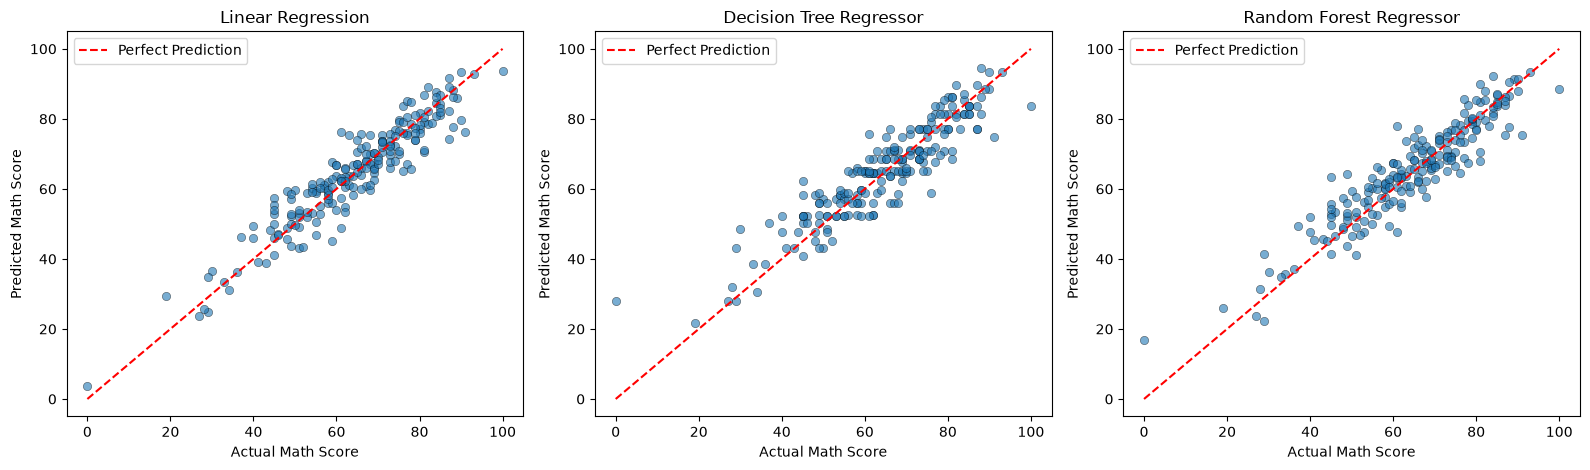

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, (name, (_, y_pred)) in zip(axes, trained_pipelines.items()):
    ax.scatter(y_test, y_pred, alpha=0.6, edgecolors="k", linewidth=0.4)
    ax.plot([0, 100], [0, 100], "r--", lw=1.5, label="Perfect Prediction")
    ax.set_title(name)
    ax.set_xlabel("Actual Math Score")
    ax.set_ylabel("Predicted Math Score")
    ax.legend()

plt.tight_layout()
plt.show()

In [5]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name][0]

os.makedirs("../backend/ml_models", exist_ok=True)
model_path = "../backend/ml_models/student_math_pipeline.joblib"
joblib.dump(best_pipeline, model_path)

print(f"Saved best model ({best_model_name}) to: {model_path}")

# Quick sanity check reload
loaded_model = joblib.load(model_path)
sample_pred = loaded_model.predict(X_test.iloc[:3])
print("Sample reloaded predictions:", np.round(sample_pred, 2))

Saved best model (Linear Regression) to: ../backend/ml_models/student_math_pipeline.joblib
Sample reloaded predictions: [76.39 58.89 76.99]


### Model Evaluation & Selection Summary
- **Winning Model:** **Linear Regression** achieved the lowest error (**MAE $\approx 4.21$**, **RMSE $\approx 5.39$**) and highest variance explained (**$R^2 \approx 0.88$**) on the held-out 20% test set.
- **Interpretation:** Reading and writing scores exhibit a strong linear relationship with math performance, allowing Linear Regression to generalize better than tree-based models (Decision Tree and Random Forest), which show slight step-wise variance on small tabular data.
- **Artifact Exported:** The full leakage-safe preprocessing and regression `Pipeline` has been serialized to `backend/ml_models/student_math_pipeline.joblib` for live Django API inference.